# ColorMNIST Ablation: Initial Particle Distribution (DR Target, IMQ MMD Flow)

The companion notebook `ColorMNIST_DR_IMQ_MMD_Flow_Euler_Arm1` initialises the flow particles at
encoded observed arm-$a^\*$ images. This ablation keeps that pipeline fixed — same data seed,
autoencoder, cross-fitted DR target, kernel, step size, and iteration budget — and varies only the
initial particle distribution:

1. **observed** $P_{Y \mid A = a^\*}$ latents (the reference);
2. $\mathcal N(0, I)$ in the latent space;
3. $\mathcal N(\hat\mu, \hat\Sigma)$ with mean and covariance moment-matched to the encoded
   observed images.

The question is whether the flow requires an on-manifold start: the objective constrains only the
mean embedding of the particle cloud, so an initialisation far from the latent manifold may match
the target embedding while decoding poorly.

In [1]:
import sys
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde

sys.path.append("../../src")
torch.set_default_dtype(torch.float32)

from data_utils import (color_ratio, load_digit_pools, sample_interventional,
                        sample_observed, to_image_range, to_model_range)
from autoencoder_utils import encode_in_batches, train_conv_ae
from kernel_utils import IMQKernel, RBF, imq_c_from_median
from causality_utils import (cpme_dr_weights_crossfit, make_crossfit_fold_ids,
                             select_regularization)
from dens_ratio_utils import crossfit_propensity
from mmd_flow_utils import mmd_gradient_flow, squared_mmd
from metric_utils import sliced_wasserstein

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


## 1. Pipeline (identical to the companion notebook)

Data, autoencoder, and the cross-fitted DR target embedding are constructed exactly as in
`ColorMNIST_DR_IMQ_MMD_Flow_Euler_Arm1`; see that notebook for the derivations.

In [2]:
N_OBS, TARGET_A = 20000, 1
W_CONF, TAU = 10.0, 0.08
N_DR, M = 4000, 1600

pools = load_digit_pools(root="../../data", device=device)
generator = torch.Generator(device=device).manual_seed(SEED)
X_obs, A_obs, Y_obs = sample_observed(pools, N_OBS, w_conf=W_CONF, tau=TAU,
                                      generator=generator)
data = to_model_range(Y_obs)
arm = A_obs == TARGET_A

ae, history_ae = train_conv_ae(data, latent_dim=32, n_iterations=3000, batch_size=128,
                               learning_rate=1e-3, device=device,
                               generator=torch.Generator(device=device).manual_seed(SEED),
                               log_every=1500, verbose=False)
for parameter in ae.parameters():
    parameter.requires_grad_(False)

subsample = torch.randperm(N_OBS, generator=torch.Generator(device=device).manual_seed(SEED + 5),
                           device=device)[:N_DR]
X_s, A_s = X_obs[subsample], A_obs[subsample]
Z_s = encode_in_batches(ae.encode, data[subsample])
fold_ids = make_crossfit_fold_ids(N_DR, n_folds=5, seed=0)
torch.manual_seed(SEED)
e1 = crossfit_propensity(X_s.unsqueeze(1).double().cpu(), A_s.double().cpu(), fold_ids)
w_hat = (A_s.cpu() == TARGET_A).double() / (e1 if TARGET_A == 1 else 1.0 - e1)

kernel_x = RBF(use_length_scale_heuristic=True)
K_x = kernel_x(X_s.unsqueeze(1).double().cpu())
K_a = (A_s[:, None] == A_s[None, :]).double().cpu()
K_a_target = (A_s == TARGET_A).double().cpu()[:, None].expand(N_DR, N_DR).contiguous()
K_pair = K_x * K_a
fold_lambdas = {}
for fold in np.unique(fold_ids):
    train = np.where(fold_ids != fold)[0]
    fold_lambdas[int(fold)], _ = select_regularization(K_pair[train][:, train],
                                                       Z_s[train, 0].double().cpu(), seed=0)
v_dr = cpme_dr_weights_crossfit(K_x, K_a, K_a_target, w_hat, fold_ids,
                                fold_lambdas).float().to(device)
print(f"reconstruction MSE {history_ae[-1][1]:.4f}   "
      f"DR weights: sum(v) = {v_dr.sum():.3f}, sum|v| = {v_dr.abs().sum():.3f}")

reconstruction MSE 0.0025   DR weights: sum(v) = 1.000, sum|v| = 1.000


## 2. The Three Initial Distributions

The encoded observed images are far from standard scale, so $\mathcal N(0, I)$ starts off the
latent manifold; the moment-matched Gaussian corrects the first two moments but not the manifold
geometry. Decoding the raw initial particles makes the difference visible before any flow is run.

latent scale: per-coordinate std 1.59 (mean over 32 dims)   mean vector norm 10.6   N(0,I) vector norm ~ sqrt(32) = 5.7


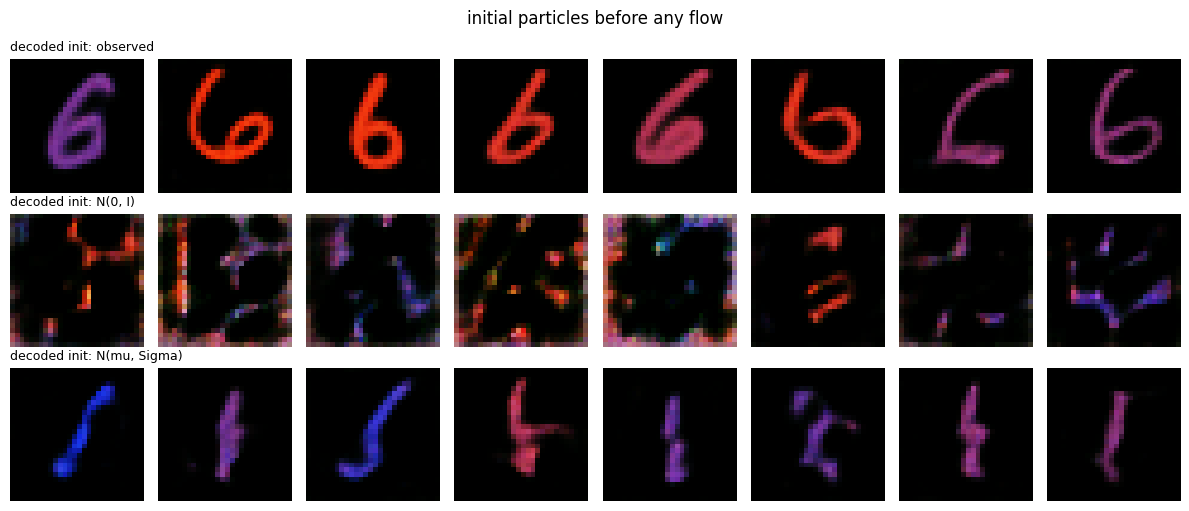

In [3]:
Z_arm = encode_in_batches(ae.encode, data[arm])
Z_all = encode_in_batches(ae.encode, data)
print(f"latent scale: per-coordinate std {Z_all.std(0).mean():.2f} (mean over 32 dims)   "
      f"mean vector norm {Z_all.norm(dim=1).mean():.1f}   "
      f"N(0,I) vector norm ~ sqrt(32) = {np.sqrt(32):.1f}")

pick = torch.randperm(Z_arm.shape[0], generator=torch.Generator(device=device).manual_seed(SEED + 1),
                      device=device)[:M]
mu_hat = Z_all.mean(0)
Sigma_hat = torch.cov(Z_all.T)
chol = torch.linalg.cholesky(Sigma_hat + 1e-3 * torch.eye(32, device=device))
standard_normal = torch.randn(M, 32, generator=torch.Generator(device=device).manual_seed(SEED + 2),
                              device=device)
initials = {
    "observed": Z_arm[pick].clone(),
    "N(0, I)": torch.randn(M, 32, generator=torch.Generator(device=device).manual_seed(SEED + 3),
                           device=device),
    "N(mu, Sigma)": mu_hat + standard_normal @ chol.T,
}

fig, axes = plt.subplots(3, 8, figsize=(12, 5.2))
with torch.no_grad():
    for r, (name, z0) in enumerate(initials.items()):
        decoded = ae.decode(z0[:8])
        for k in range(8):
            axes[r, k].imshow(to_image_range(decoded[k]).permute(1, 2, 0).cpu().numpy())
            axes[r, k].axis("off")
        axes[r, 0].set_title(f"decoded init: {name}", fontsize=9, loc="left")
fig.suptitle("initial particles before any flow", fontsize=12)
fig.tight_layout()
plt.show()

## 3. One Flow per Initialisation

Same kernel, step size, target weights, and iteration budget for all three.

observed       objective 1.67e-03 -> 9.58e-06


N(0, I)        objective 8.46e-03 -> 7.19e-05


N(mu, Sigma)   objective 2.79e-03 -> 4.69e-05


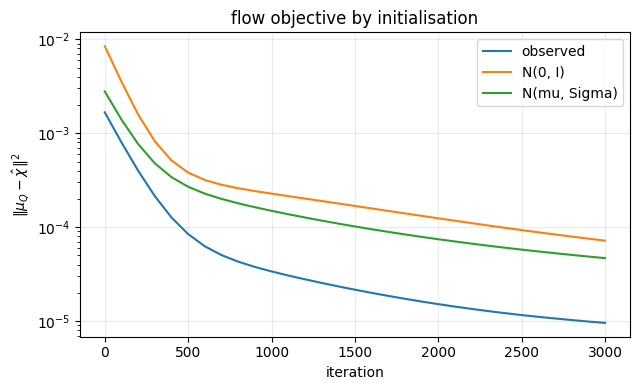

In [4]:
c_imq = imq_c_from_median(Z_s)
kernel = IMQKernel(c=c_imq, beta=-0.5)
step_size = 0.15 * c_imq ** 2

flowed, histories = {}, {}
for name, z0 in initials.items():
    flowed[name], histories[name] = mmd_gradient_flow(
        kernel, target_samples=Z_s, initial_particles=z0.clone(),
        step_size=step_size, n_iterations=3000, target_weights=v_dr,
        log_every=100, verbose=False)
    print(f"{name:14s} objective {histories[name]['squared_mmd'][0]:.2e} -> "
          f"{histories[name]['squared_mmd'][-1]:.2e}")

plt.figure(figsize=(6.5, 4))
for name, history in histories.items():
    plt.semilogy(history["iterations"], history["squared_mmd"], label=name)
plt.xlabel("iteration")
plt.ylabel(r"$\Vert \mu_Q - \hat\chi \Vert^2$")
plt.legend()
plt.title("flow objective by initialisation")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 4. Decoded Samples and Colour Law

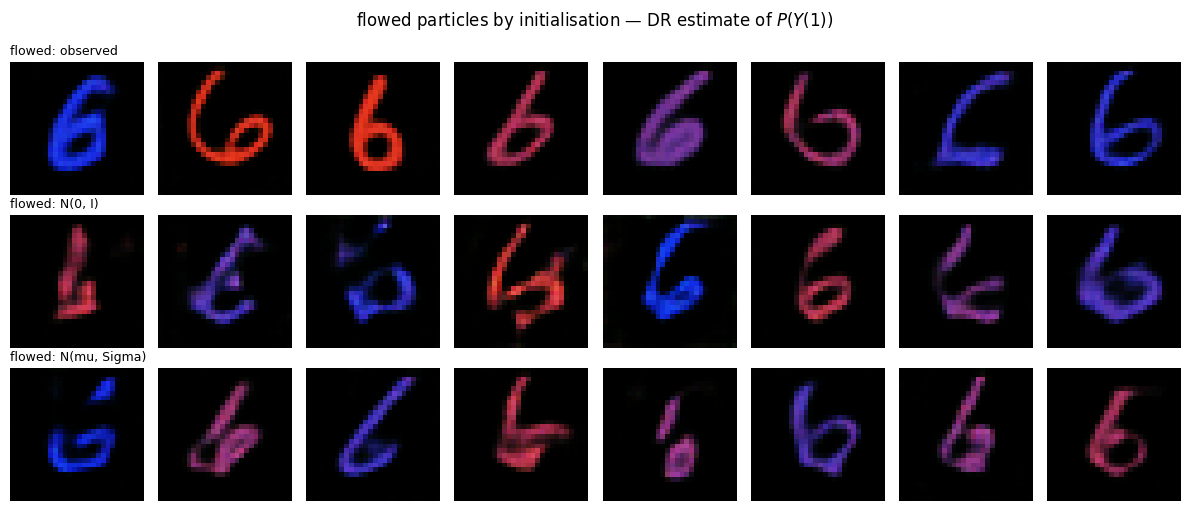

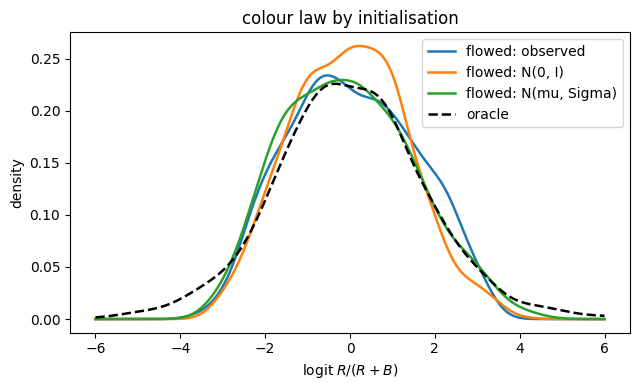

In [5]:
_, Y_oracle = sample_interventional(pools, M, a=TARGET_A, tau=TAU,
                                    generator=torch.Generator(device=device).manual_seed(SEED + 9))
fig, axes = plt.subplots(3, 8, figsize=(12, 5.2))
decoded_flowed = {}
with torch.no_grad():
    for r, (name, particles) in enumerate(flowed.items()):
        decoded_flowed[name] = ae.decode(particles)
        for k in range(8):
            axes[r, k].imshow(to_image_range(decoded_flowed[name][k]).permute(1, 2, 0).cpu().numpy())
            axes[r, k].axis("off")
        axes[r, 0].set_title(f"flowed: {name}", fontsize=9, loc="left")
fig.suptitle(f"flowed particles by initialisation — DR estimate of $P(Y({TARGET_A}))$", fontsize=12)
fig.tight_layout()
plt.show()

logit = lambda p: np.log(np.clip(p, 1e-4, 1 - 1e-4) / (1 - np.clip(p, 1e-4, 1 - 1e-4)))
grid = np.linspace(-6, 6, 400)
oracle_colour = color_ratio(Y_oracle).cpu().numpy()
plt.figure(figsize=(6.5, 4))
for name, images in decoded_flowed.items():
    values = color_ratio(to_image_range(images)).cpu().numpy()
    plt.plot(grid, gaussian_kde(logit(values))(grid), lw=1.8, label=f"flowed: {name}")
plt.plot(grid, gaussian_kde(logit(oracle_colour))(grid), "--", lw=1.8, c="k", label="oracle")
plt.xlabel(r"$\mathrm{logit}\; R/(R+B)$")
plt.ylabel("density")
plt.legend()
plt.title("colour law by initialisation")
plt.tight_layout()
plt.show()

## 5. Metric Evaluation

As in the companion notebook: colour moments, sliced Wasserstein distances of both orders, and
unbiased squared MMD against an oracle draw, with a second draw giving the floors. An additional
column reports the autoencoder cycle error $\lVert \mathrm{enc}(\mathrm{dec}(z)) - z \rVert$ of the
flowed particles, a manifold-validity score: latents the decoder renders faithfully re-encode to
themselves.

In [6]:
_, Y_oracle_2 = sample_interventional(pools, M, a=TARGET_A, tau=TAU,
                                      generator=torch.Generator(device=device).manual_seed(SEED + 10))
flatten = lambda images: images.reshape(images.shape[0], -1)
kernel_pixel = RBF(use_length_scale_heuristic=True)
_ = kernel_pixel(flatten(Y_oracle))


@torch.no_grad()
def cycle_error(z):
    return (encode_in_batches(ae.encode, ae.decode(z)) - z).norm(dim=1).mean().item()


print(f"{'initialisation':16s} {'colour mean(std)':>18s} {'SW1':>8s} {'SW2':>8s} "
      f"{'MMD^2':>10s} {'cycle':>7s}")
for name, images in decoded_flowed.items():
    images_01 = to_image_range(images)
    ratio = color_ratio(images_01).cpu().numpy()
    sw1 = sliced_wasserstein(flatten(images_01), flatten(Y_oracle), p=1, seed=0).item()
    sw2 = sliced_wasserstein(flatten(images_01), flatten(Y_oracle), p=2, seed=0).item()
    mmd2 = squared_mmd(kernel_pixel, flatten(images_01), flatten(Y_oracle), unbiased=True).item()
    print(f"{name:16s} {ratio.mean():>11.3f}({ratio.std():.3f}) {sw1:8.4f} {sw2:8.4f} "
          f"{mmd2:10.2e} {cycle_error(flowed[name]):7.2f}")
sw1_floor = sliced_wasserstein(flatten(Y_oracle_2), flatten(Y_oracle), p=1, seed=0).item()
sw2_floor = sliced_wasserstein(flatten(Y_oracle_2), flatten(Y_oracle), p=2, seed=0).item()
mmd2_floor = squared_mmd(kernel_pixel, flatten(Y_oracle_2), flatten(Y_oracle), unbiased=True).item()
ratio_floor = color_ratio(Y_oracle_2).cpu().numpy()
cycle_obs = cycle_error(initials["observed"])
print(f"{'oracle floor':16s} {ratio_floor.mean():>11.3f}({ratio_floor.std():.3f}) "
      f"{sw1_floor:8.4f} {sw2_floor:8.4f} {mmd2_floor:10.2e} {'-':>7s}")
print(f"\ncycle error of raw observed latents (reference): {cycle_obs:.2f}")

initialisation     colour mean(std)      SW1      SW2      MMD^2   cycle
observed               0.506(0.280)   0.0091   0.0134   1.77e-03    1.01
N(0, I)                0.496(0.260)   0.0193   0.0260   1.27e-02    3.28
N(mu, Sigma)           0.488(0.281)   0.0149   0.0205   6.83e-03    3.00
oracle floor           0.494(0.286)   0.0055   0.0081  -1.07e-04       -

cycle error of raw observed latents (reference): 0.79
